In [2]:
# 1.2 The Words You Will Meet

# | Word       | Meaning                                      | In Our Project       |
# |------------|----------------------------------------------|----------------------|
# | Layer      | A group of neurons                           | Three Dense layers   |
# | Weights    | Numbers the network learns                   | 6,570 of them        |
# | Activation | Adds non-linearity to a layer                | ReLU and softmax     |
# | Loss       | How wrong the predictions are                | Cross-entropy        |
# | Optimizer  | Changes weights to reduce the loss           | Adam                 |
# | Epoch      | One full pass over the training data         | 30 passes            |
# | Batch      | A small group of rows used per update        | 32 images            |

In [3]:
import sys
print(sys.version)
print(sys.executable)

3.12.0 (tags/v3.12.0:0fb18b0, Oct  2 2023, 13:03:39) [MSC v.1935 64 bit (AMD64)]
c:\Python312\python.exe


In [4]:
import sys
print(sys.executable)

import tensorflow as tf
print(tf.__version__)

c:\Python312\python.exe
2.21.0


In [5]:
import numpy as np
import tensorflow as tf
import keras

print(tf.__version__)
print(keras.__version__)

2.21.0
3.15.1


In [6]:
from sklearn.datasets import load_digits

digits = load_digits()
X = digits.data / 1.0
y = digits.target

print(X.shape, y.shape)
print(X.min(), X.max())
print(np.bincount(y))

(1797, 64) (1797,)
0.0 16.0
[178 182 177 183 181 182 181 179 174 180]


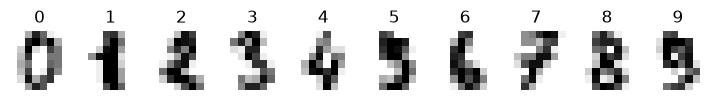

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 10, figsize=(9, 2))
for i , ax in enumerate(axes):
    idx = (y == i).argmax()
    img = digits.images[idx]
    ax.imshow(img, cmap='gray_r')
    ax.set_title(i)
    ax.axis('off')


plt.show()

In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_test, y_test, test_size=0.5, random_state=42)
print(X_train.shape, X_val.shape, X_test.shape)

(1078, 64) (359, 64) (360, 64)


In [9]:
import keras
from keras import layers

keras.utils.set_random_seed(42)
model = keras.Sequential([
    keras.Input(shape=(64,)),
    layers.Dense(64, activation='relu'),
    layers.Dense(32, activation='relu'),
    layers.Dense(10, activation='softmax')
])

In [10]:
for layer in model.layers:
    print(layer.name, layer.units, layer.count_params())
    print("Total:", model.count_params())

dense 64 4160
Total: 6570
dense_1 32 2080
Total: 6570
dense_2 10 330
Total: 6570


In [11]:
# 3.4 Counting the Weights by Hand

# | Layer   | Calculation                | Weights |
# |---------|----------------------------|---------|
# | Dense 1 | 64 inputs x 64 neurons + 64 biases | 4,160 |
# | Dense 2 | 64 x 32 + 32 biases        | 2,080 |
# | Dense 3 | 32 x 10 + 10 biases        | 330     |
# | Total   | 4,160 + 2,080 + 330       | 6,570   |



In [12]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)


In [13]:
history = model.fit(
    X_train,y_train,
    epochs=30,batch_size=32,
    validation_data=(X_val,y_val),verbose=0)

In [14]:
h=history.history
for key in h:
    print(key,round(h[key][0],3),
          round(h[key][-1],3))

accuracy 0.348 1.0
loss 2.688 0.006
val_accuracy 0.515 0.978
val_loss 1.575 0.078


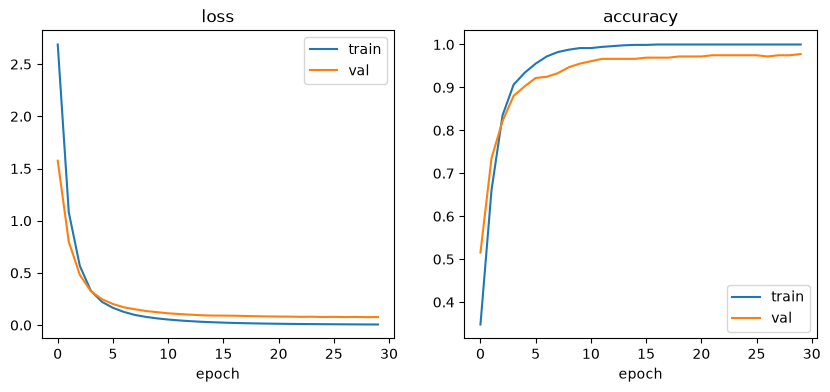

In [15]:
def plot_history(h):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    names = ["loss", "accuracy"]
    for ax, k in zip(axes, names):
        ax.plot(h[k], label='train')
        ax.plot(h['val_' + k], label='val')
        ax.set_title(k)
        ax.set_xlabel('epoch')
        ax.legend()
    plt.show()

plot_history(history.history)

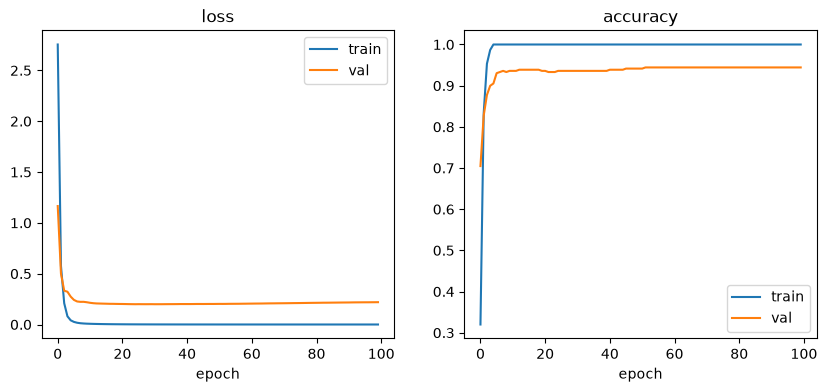

In [16]:
LOSS = "sparse_categorical_crossentropy"

def make_model(units=(64, 32)):
    keras.utils.set_random_seed(42)
    m = keras.Sequential([keras.Input(shape= (64,))])
    for u in units:
        m.add(keras.layers.Dense(u, activation='relu'))
    m.add(keras.layers.Dense(10, activation='softmax'))
    m.compile(optimizer='adam', loss=LOSS, metrics=['accuracy'])
    return m
big=make_model((256,256))
small_hist=big.fit(
    X_train[:150],y_train[:150],
    epochs=100,batch_size=16,
    validation_data=(X_val,y_val),verbose=0
)
plot_history(small_hist.history)

In [17]:
b = small_hist.history
best = int(np.argmin(b['val_loss'])) + 1
print(f"Best epoch: {best}")
print("lowest val loss:", round(min(b['val_loss']), 3))
print("Final val loss:", round(b["val_loss"][-1], 3))
print("Final train loss:", round(b["loss"][-1], 4))

Best epoch: 31
lowest val loss: 0.2
Final val loss: 0.22
Final train loss: 0.0001


In [18]:
big2 = make_model((256, 256))
full = big2.fit(
    X_train, y_train,
    epochs=30, batch_size=16,
    validation_data=(X_val, y_val),
    verbose=0)

a1 = small_hist.history["val_accuracy"][-1]
a2 = full.history["val_accuracy"][-1]
print("150 rows: ", round(a1, 3))
print("1078 rows: ", round(a2, 3))

150 rows:  0.944
1078 rows:  0.981


In [19]:
stop=keras.callbacks.EarlyStopping(
    monitor="val_loss",patience=5,
    restore_best_weights=True)
final=make_model()
hist=final.fit(
    X_train,y_train,epochs=200,
    batch_size=32,
    validation_data=(X_val,y_val),
    callbacks=[stop],verbose=0)
print("epochs run:",len(hist.history["loss"]))
print("best epoch:",stop.best_epoch+1)

epochs run: 44
best epoch: 39


In [20]:
loss, acc = final.evaluate(X_test, y_test, verbose=0)
print("Test loss:", round(loss, 3))
print("Test accuracy:", round(acc, 3))

Test loss: 0.126
Test accuracy: 0.978


In [21]:
probs = final.predict(X_test, verbose=0)
pred = np.argmax(probs, axis=1)
print("confidence:", probs[0].max().round(3))
print(pred[:10], y_test[:10])
print("Mistakes:", (pred != y_test).sum())

confidence: 1.0
[2 4 6 3 8 0 5 1 5 8] [2 4 6 3 8 0 5 1 5 8]
Mistakes: 8


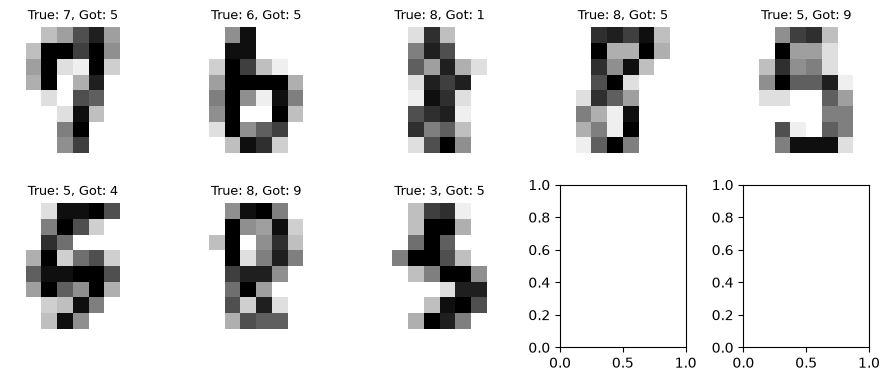

In [22]:
import numpy as np
import matplotlib.pyplot as plt

# Find incorrectly predicted samples
wrong = np.where(pred != y_test)[0][:10]

# Create a grid of 2 rows and 5 columns
fig, axes = plt.subplots(2, 5, figsize=(9, 4))

for ax, i in zip(axes.flat, wrong):
    img = X_test[i].reshape(8, 8)

    ax.imshow(img, cmap='gray_r')

    label = f'True: {y_test[i]}, Got: {pred[i]}'
    ax.set_title(label, fontsize=9)
    ax.axis('off')

plt.tight_layout()
plt.show()

In [23]:
final.save("digits.keras")
loaded = keras.models.load_model("digits.keras")
same = loaded.predict(X_test[:5], verbose=0)
print(np.argmax(same, axis = 1))

[2 4 6 3 8]
